<a href="https://colab.research.google.com/github/rahulraj710/AML-CID/blob/main/notebooks/02_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv("/content/AML_CID_practice_sample.csv")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)

display(df.head())

print(df["Label"].value_counts())

Dataset shape: (28307, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,80,204,2,0,0,0,0,0,0.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,53,336,2,2,82,338,41,41,41.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,53,255,2,2,104,352,52,52,52.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,53,190,2,2,88,188,44,44,44.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,15122,6983953,1,5,6,30,6,6,6.0,0.0,...,32424.0,0.0,32424,32424,6951529.0,0.0,6951529,6951529,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


Label
BENIGN                      22734
DoS Hulk                     2336
PortScan                     1593
DDoS                         1278
DoS GoldenEye                  99
FTP-Patator                    72
DoS Slowhttptest               54
SSH-Patator                    54
DoS slowloris                  49
Bot                            18
Web Attack � Brute Force       13
Web Attack � XSS                7
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/cicids2017_combined.csv"

df = pd.read_csv(file_path, nrows=10000)

df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())

(10000, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [ ]:

import pandas as pd

file_path = "/content/drive/MyDrive/cicids2017_combined.csv"

label_counts = pd.Series(dtype="int64")
total_rows = 0

# Read the dataset in groups of 50,000 rows
for chunks in pd.read_csv(file_path, chunksize=50000):

    # Clean column names
    chunks.columns = chunks.columns.str.strip()

    # Count each traffic category
    counts = chunks["Label"].value_counts()

    # Combine counts
    label_counts = label_counts.add(counts, fill_value=0)

    # Count the total rows
    total_rows += len(chunks)

# Display the results
label_counts = label_counts.astype(int)

print("Total records:", total_rows)
print("\nTraffic categories:")
print(label_counts.sort_values(ascending=False))


Total records: 2830743

Traffic categories:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
dtype: int64


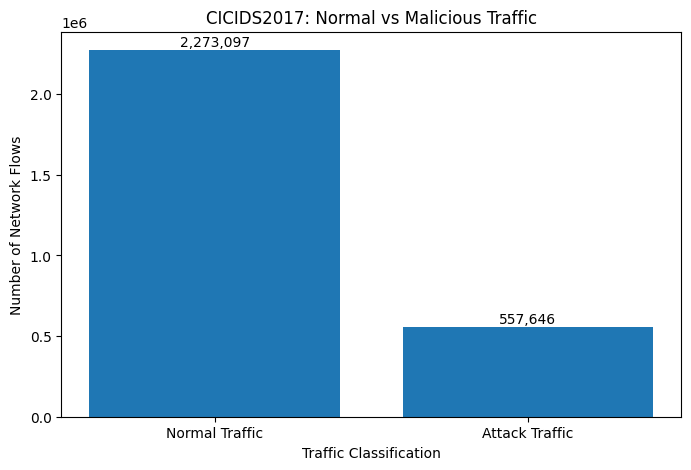

In [ ]:

import matplotlib.pyplot as plt

# Combine the 14 attack categories into one group
normal = label_counts["BENIGN"]
attacks = label_counts.sum() - normal

# Create our two categories
categories = ["Normal Traffic", "Attack Traffic"]
values = [normal, attacks]

# Create the graph
plt.figure(figsize=(8, 5))
plt.bar(categories, values)

# Add a title and labels
plt.title("CICIDS2017: Normal vs Malicious Traffic")
plt.xlabel("Traffic Classification")
plt.ylabel("Number of Network Flows")

# Add record counts above the bars
for i, value in enumerate(values):
    plt.text(i, value + 20000, f"{value:,}", ha="center")

# Save the graph for our report
plt.savefig("traffic_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()


In [1]:

import pandas as pd
import numpy as np
import os

from google.colab import drive
drive.mount("/content/drive")

file_path = "/content/drive/MyDrive/cicids2017_combined.csv"

print("Dataset found:", os.path.exists(file_path))


Mounted at /content/drive
Dataset found: True


In [2]:

sample_parts = []

for i, chunk in enumerate(
    pd.read_csv(file_path, chunksize=50000, low_memory=False)
):
    chunk.columns = chunk.columns.str.strip()

    sampled_chunk = chunk.sample(
        frac=0.05,
        random_state=42 + i
    )

    sample_parts.append(sampled_chunk)

df = pd.concat(sample_parts, ignore_index=True)

print("Sample shape:", df.shape)
print(df["Label"].value_counts())


Sample shape: (141537, 80)
Label
BENIGN                      113612
DoS Hulk                     11552
PortScan                      7956
DDoS                          6418
DoS GoldenEye                  472
FTP-Patator                    417
SSH-Patator                    308
DoS slowloris                  296
DoS Slowhttptest               293
Bot                             91
Web Attack � Brute Force        69
Web Attack � XSS                50
Infiltration                     2
Heartbleed                       1
Name: count, dtype: int64


In [3]:

# Clean up the original labels
df["Label"] = df["Label"].astype("string").str.strip()

# Check for missing labels before converting
print("Missing labels:", df["Label"].isna().sum())

# Create binary classifications
df["Binary_Label"] = (df["Label"] != "BENIGN").astype(int)

print("\nBinary traffic counts:")
print(df["Binary_Label"].value_counts())


Missing labels: 0

Binary traffic counts:
Binary_Label
0    113612
1     27925
Name: count, dtype: int64


In [4]:

# Separate the target from the input features
y = df["Binary_Label"]

# Remove labels and source information from the inputs
X = df.drop(
    columns=["Label", "Binary_Label", "source_file"]
)

# Remove the redundant column identified during EDA
X = X.drop(columns=["Fwd Header Length.1"])

# Convert feature values to numbers
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinity with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", X.isna().sum().sum())
print("Remaining infinite values:",
      np.isinf(X.to_numpy()).sum())


Feature matrix shape: (141537, 77)
Target shape: (141537,)
Missing feature values: 268
Remaining infinite values: 0


In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())


Training records: 113229
Testing records: 28308

Training labels:
Binary_Label
0    90889
1    22340
Name: count, dtype: int64

Testing labels:
Binary_Label
0    22723
1     5585
Name: count, dtype: int64


In [6]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created!")


Logistic Regression pipeline created!


In [7]:

import time

# Start measuring training time
start_time = time.time()

# Train the Logistic Regression model
baseline_model.fit(X_train, y_train)

# Calculate training duration
training_time = time.time() - start_time

print("Logistic Regression training complete!")
print(f"Training time: {training_time:.2f} seconds")


Logistic Regression training complete!
Training time: 10.44 seconds


In [8]:

# Predict whether test traffic is normal or malicious
y_pred = baseline_model.predict(X_test)

# Display some predictions
print("First 10 predictions:")
print(y_pred[:10])

print("\nActual classifications:")
print(y_test.iloc[:10].to_numpy())


First 10 predictions:
[1 0 0 0 1 1 0 0 1 0]

Actual classifications:
[1 0 0 0 0 1 0 0 1 0]


In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.93856860251519
Precision: 0.8578340156308151
Recall: 0.8254252461951657
F1-score: 0.8413176384706634

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.97      0.96     22723
      Attack       0.86      0.83      0.84      5585

    accuracy                           0.94     28308
   macro avg       0.91      0.90      0.90     28308
weighted avg       0.94      0.94      0.94     28308


Confusion Matrix:
[[21959   764]
 [  975  4610]]


In [10]:

import time
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

weighted_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

start_time = time.time()

weighted_model.fit(X_train, y_train)

weighted_training_time = time.time() - start_time

print("Weighted Logistic Regression trained!")
print(f"Training time: {weighted_training_time:.2f} seconds")


Weighted Logistic Regression trained!
Training time: 16.71 seconds


In [11]:

weighted_pred = weighted_model.predict(X_test)

print("Weighted Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, weighted_pred))

print("Precision:",
      precision_score(y_test, weighted_pred))

print("Recall:",
      recall_score(y_test, weighted_pred))

print("F1-score:",
      f1_score(y_test, weighted_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, weighted_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    weighted_pred,
    target_names=["Normal", "Attack"]
))


Weighted Logistic Regression Results
Accuracy: 0.9159248269040554
Precision: 0.7158830661457631
Recall: 0.9514771709937332
F1-score: 0.8170356703567035

Confusion Matrix:
[[20614  2109]
 [  271  5314]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.91      0.95     22723
      Attack       0.72      0.95      0.82      5585

    accuracy                           0.92     28308
   macro avg       0.85      0.93      0.88     28308
weighted avg       0.93      0.92      0.92     28308



In [12]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Baseline", "Class-weighted"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, weighted_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, weighted_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, weighted_pred)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, weighted_pred)
    ],
    "False Negatives": [
        confusion_matrix(y_test, y_pred)[1, 0],
        confusion_matrix(y_test, weighted_pred)[1, 0]
    ],
    "False Positives": [
        confusion_matrix(y_test, y_pred)[0, 1],
        confusion_matrix(y_test, weighted_pred)[0, 1]
    ]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-score,False Negatives,False Positives
0,Baseline,0.9386,0.8578,0.8254,0.8413,975,764
1,Class-weighted,0.9159,0.7159,0.9515,0.8170,271,2109


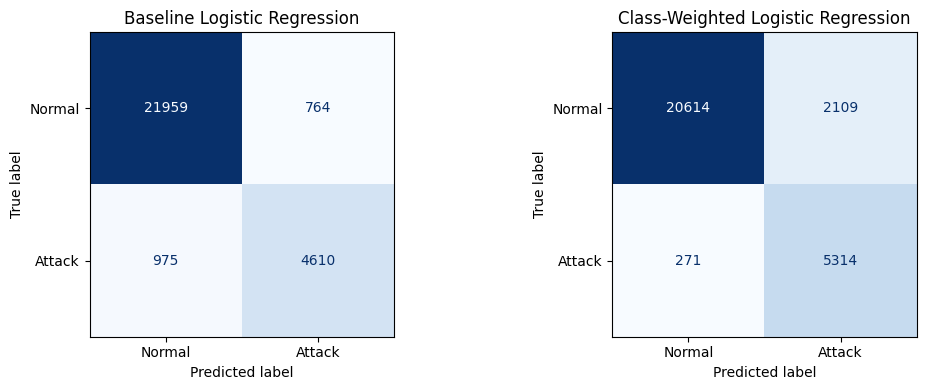

In [13]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Normal", "Attack"],
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)
axes[0].set_title("Baseline Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, weighted_pred,
    display_labels=["Normal", "Attack"],
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)
axes[1].set_title("Class-Weighted Logistic Regression")

plt.tight_layout()
plt.savefig(
    "logistic_regression_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


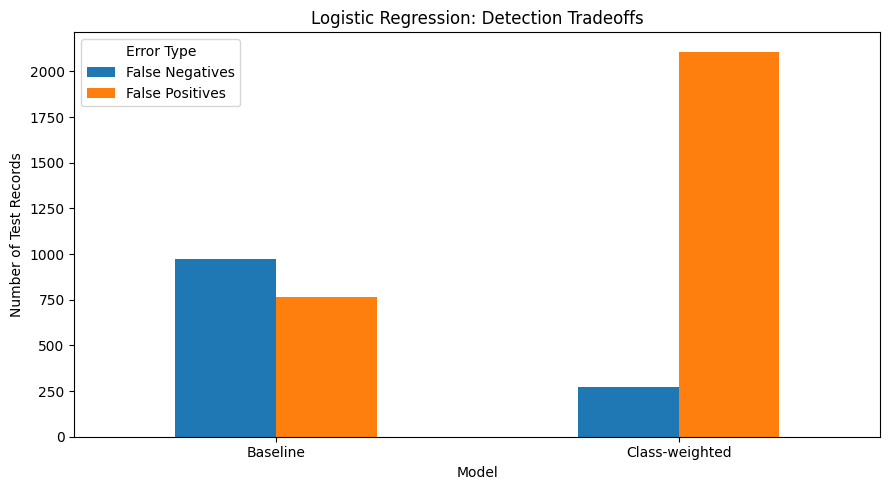

In [14]:

comparison_plot = comparison.set_index("Model")[
    ["False Negatives", "False Positives"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Logistic Regression: Detection Tradeoffs")
plt.ylabel("Number of Test Records")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Error Type")

plt.tight_layout()
plt.savefig(
    "logistic_regression_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Business and Cybersecurity Management Implications

Our Logistic Regression experiments showed that class weighting improved the model's ability to identify malicious network traffic. Attack recall increased from 82.54% to 95.15%, reducing missed attacks from 975 to 271.

However, this improvement came with a tradeoff. False positives increased from 764 to 2,109, meaning the weighted model incorrectly classified more legitimate network traffic as malicious.

From a cybersecurity management perspective, these results demonstrate the importance of balancing security effectiveness with operational efficiency. Missed attacks can expose an organization to data breaches, financial losses, and business interruptions. At the same time, excessive false alarms can increase the workload of security analysts and the resources required to investigate suspicious activity.

An organization with a high risk of cyberattacks may prioritize detection and accept additional false positives. An organization with limited cybersecurity staffing may need to consider whether the additional alerts are manageable.

Therefore, the best model cannot be selected based on accuracy alone. Management must consider recall, precision, investigation costs, operational resources, and the potential consequences of undetected attacks.

These findings are preliminary because the experiments used a 5% sample of CICIDS2017 and a random training/test split. Further validation is needed before determining which model would be most appropriate for organizational use.

In [15]:

from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Training records:", len(X_train_new))
print("Validation records:", len(X_val))

print("\nValidation class distribution:")
print(y_val.value_counts())


Training records: 84921
Validation records: 28308

Validation class distribution:
Binary_Label
0    22723
1     5585
Name: count, dtype: int64


In [16]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = []

settings = [
    ("Baseline C=1", None, 1.0),
    ("Baseline C=0.1", None, 0.1),
    ("Balanced C=1", "balanced", 1.0),
    ("Balanced C=0.1", "balanced", 0.1)
]

for name, weight, c_value in settings:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight=weight,
            C=c_value,
            max_iter=1000,
            random_state=42
        ))
    ])

    model.fit(X_train_new, y_train_new)

    predictions = model.predict(X_val)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "False Positives": fp,
        "False Negatives": fn
    })

print("All four models evaluated!")


All four models evaluated!


In [17]:

import pandas as pd

validation_results = pd.DataFrame(results)

display(
    validation_results.round(4).sort_values(
        by="F1",
        ascending=False
    )
)


,Model,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,Baseline C=1,0.9367,0.8552,0.8177,0.8361,773,1018
1,Baseline C=0.1,0.9329,0.8501,0.8011,0.8249,789,1111
2,Balanced C=1,0.9128,0.7090,0.9466,0.8108,2170,298
3,Balanced C=0.1,0.9076,0.6970,0.9404,0.8006,2283,333


In [18]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

threshold_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

# Train only on the new training portion
threshold_model.fit(X_train_new, y_train_new)

# Get predicted attack probabilities for validation data
val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

print("Model trained successfully!")
print("First 10 attack probabilities:")
print(val_probabilities[:10])


Model trained successfully!
First 10 attack probabilities:
[1.35482414e-02 4.01976014e-02 4.56478037e-06 7.34879052e-04
 1.68900669e-19 7.59302326e-01 1.85649083e-03 3.44411293e-04
 9.99999995e-01 3.98582124e-02]


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,0.3,0.9339,0.7789,0.9284,0.8471,1472,400
1,0.4,0.9318,0.7939,0.8836,0.8364,1281,650
2,0.5,0.9367,0.8552,0.8177,0.8361,773,1018
3,0.6,0.9266,0.8826,0.7241,0.7955,538,1541
4,0.7,0.9184,0.9123,0.6485,0.7581,348,1963


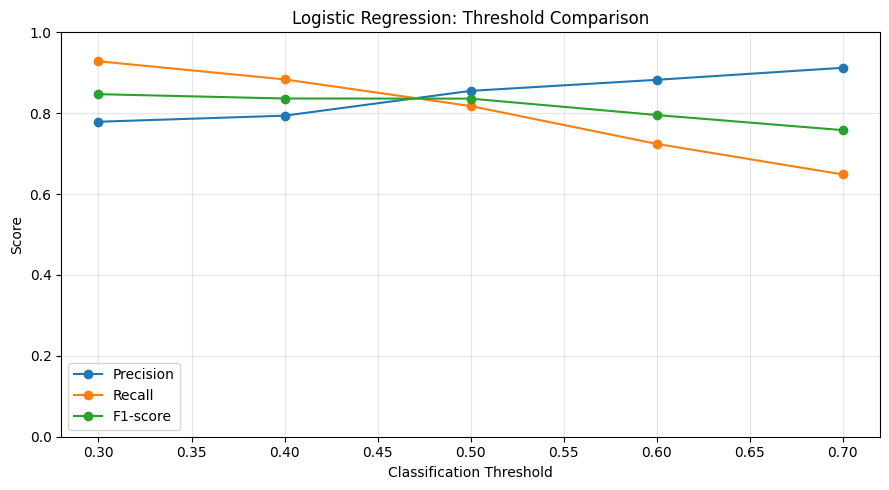

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.title("Logistic Regression: Threshold Comparison")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "logistic_regression_threshold_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [21]:

# Hypothetical cost assumptions
cost_per_false_alarm = 25
cost_per_missed_attack = 500

business_results = threshold_df.copy()

business_results["Estimated Cost"] = (
    business_results["False Positives"] * cost_per_false_alarm
    + business_results["False Negatives"] * cost_per_missed_attack
)

display(
    business_results[
        ["Threshold", "False Positives",
         "False Negatives", "Estimated Cost"]
    ].sort_values("Estimated Cost")
)

best_business_threshold = business_results.loc[
    business_results["Estimated Cost"].idxmin(),
    "Threshold"
]

print(
    "Lowest estimated-cost threshold:",
    best_business_threshold
)


,Threshold,False Positives,False Negatives,Estimated Cost
0,0.3,1472,400,236800
1,0.4,1281,650,357025
2,0.5,773,1018,528325
3,0.6,538,1541,783950
4,0.7,348,1963,990200


Lowest estimated-cost threshold: 0.3
